### Figure 1a
Cell population dynamics -/+ erlotinib on different substrate stiffnesses

#### Load libraries
Should use ECM_model conda environment (see README)

In [20]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
import seaborn as sns
import math

#### Set global parameters
`SAVEFILES` = logical whether to write files to disk  
`OVERWRITE` = logical whether to overwrite files if already exist
`SAVEPATH` = Path (outside of git repo) to save output files

In [22]:
SAVEFILES = True
OVERWRITE = False
SAVEPATH = os.path.expanduser("~\\ECM_mod_output")

#### Load total cell counts from .txt files

In [24]:
rcParams.update({'figure.autolayout': True})
file_location = os.path.join('..\\..\\Data\\Exp_Cell_Counts\\DIP_DS8*.txt')
filenames = glob.glob(file_location)

#### Calculate the average cell number and standard deviation as a function of time for each condition.
All cell population data is in terms of population doublings (log2). Included is the linear fit after 72 hours of treatment, the Drug Induced Proliferation (DIP) rate. *Tyson, D., Garbett, S., Frick, P. et al. Fractional proliferation: a method to deconvolve cell population dynamics from single-cell data. Nat Methods 9, 923–928 (2012)*

In [25]:
all_response = []
for f in filenames:
    all_response.append(np.loadtxt(f,delimiter=','))

means=[]
for vals in range(len(all_response)):
    means.append(np.mean(all_response[vals],axis=1))
    
stdevs=[]
for vals in range(len(all_response)):
    stdevs.append(np.std(all_response[vals],axis=1))
 
    
t = np.arange(0,420/3,1/3)
t1 = np.arange(0,363/3,1/3)

lin_fits = []
for ii in range(4):
    coef = np.polyfit(t[215:],means[ii][215:],deg=1)
    poly1d_fn = np.poly1d(coef)
    lin_fits.append(poly1d_fn(t[215:]))
    
for ii in range(4,6):
    coef = np.polyfit(t1[215:],means[ii][215:],deg=1)
    poly1d_fn = np.poly1d(coef)
    lin_fits.append(poly1d_fn(t1[215:]))

#### Plot total cell population response on 0.2, 4, and 55 kPa substrates +/- erlotinib
All cell numbers are in terms of population doublings (log2).

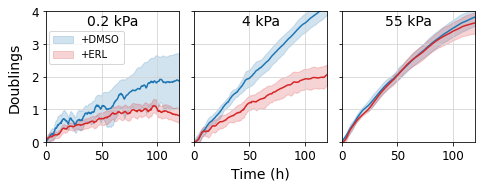

In [27]:
win = 21
pol = 2
size = (7,3)
c1 = "tab:blue"
c2 = "tab:red"
xmin = 0
xmax = 120
ymin = 0
ymax = 4

fig, axes = plt.subplots(1, 3, figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

axes[0].plot(t, savgol_filter(means[0],win,pol), color=c1)
axes[0].fill_between(t, savgol_filter(means[0] - stdevs[0],win,pol),
                     savgol_filter(means[0] + stdevs[0],win,pol), color=c1, alpha=0.2, label='+DMSO')
axes[0].plot(t, savgol_filter(means[1],win,pol), color=c2)
axes[0].fill_between(t, savgol_filter(means[1] - stdevs[1],win,pol),
                     savgol_filter(means[1] + stdevs[1],win,pol), color=c2, alpha=0.2, label='+ERL')
axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('0.2 kPa')
axes[0].grid(color='lightgray')
axes[0].legend(loc=(0.02,0.6))

axes[1].plot(t, savgol_filter(means[2],win,pol), color=c1)
axes[1].fill_between(t, savgol_filter(means[2] - stdevs[2],win,pol), 
                     savgol_filter(means[2] + stdevs[2],win,pol), color=c1, alpha=0.2)
axes[1].plot(t, savgol_filter(means[3],win,pol), color=c2)
axes[1].fill_between(t, savgol_filter(means[3] - stdevs[3],win,pol), 
                     savgol_filter(means[3] + stdevs[3],win,pol), color=c2, alpha=0.2)
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].axes.yaxis.set_ticklabels([])
axes[1].title.set_text('4 kPa')
axes[1].grid(color='lightgray')

axes[2].plot(t1, savgol_filter(means[4],win,pol), color=c1)
axes[2].fill_between(t1, savgol_filter(means[4] - stdevs[4],win,pol), 
                     savgol_filter(means[4] + stdevs[4],win,pol), color=c1, alpha=0.2)
axes[2].plot(t1, savgol_filter(means[5],win,pol), color=c2)
axes[2].fill_between(t1, savgol_filter(means[5] - stdevs[5],win,pol), 
                     savgol_filter(means[5] + stdevs[5],win,pol), color=c2, alpha=0.2)
axes[2].set_xlim([xmin, xmax])
axes[2].set_ylim([ymin, ymax])
axes[2].axes.yaxis.set_ticklabels([])
axes[2].title.set_text('55 kPa')
axes[2].grid(color='lightgray')


    
ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('Time (h)', labelpad=25)
ax.set_ylabel('Doublings', labelpad=25)
fig.tight_layout(rect=(0, 0, 1, 1))

if SAVEFILES:
    plt.savefig('C:\\Users\Austin\Documents\\UMAP_projects\\nsclc_model\\fig1a.svg', bbox_inches='tight')

In [5]:
#file_location = os.path.join('C:\\Users\\Austin\\Desktop\\cell_model\\fig_data', '*imt*')
file_location = os.path.join('*imt*.csv')
filenames = glob.glob(file_location)

In [6]:
filenames

['02kpa_dmso_imt_190118.csv',
 '02kpa_erl_imt_190118.csv',
 '06kpa_dmso_imt_181017.csv',
 '06kpa_erl_imt_181017.csv',
 '4kpa_dmso_imt_190118.csv',
 '4kpa_erl_imt_190118.csv',
 '55kpa_dmso_imt_181017.csv',
 '55kpa_erl_imt_181017.csv']

In [7]:
IMTs = []
for f in filenames:
    tmp_df = pd.read_csv(f)
    tmp_df = tmp_df.replace(to_replace=-1, value=np.nan)
    IMTs.append(tmp_df)

ii=0
for df in IMTs:
    df["IMT"] = df["Division"] - df["Mitotic Frame"]
    df["G1"] = df["Green On"] - df["Mitotic Frame"]
    df["S-M"] = df["Division"] - df["Green On"]
    if ii == 2 or ii == 3 or ii == 6 or ii == 7:
        df["IMT_t"] = df["IMT"] * (32/60)
        df["G1_t"] = df["G1"] * (32/60)
        df["S-M_t"] = df["S-M"] * (32/60)
    else:
        df["IMT_t"] = df["IMT"] * (20/60)
        df["G1_t"] = df["G1"] * (20/60)
        df["S-M_t"] = df["S-M"] * (20/60)
    #df = df[(df["IMT_t"] ==27)].reset_index(drop=True)
    ii+=1
    
stiffs = [0.2, 0.2, 0.6, 0.6, 4, 4, 55, 55]
ii=0
for df in IMTs:
    tmp_stiff = np.ones(len(df))*stiffs[ii]
    df.insert(0, "Stiffness", tmp_stiff)
    if ii % 2 == 0:
        df["Drug"] = "DMSO"
    else:
        df["Drug"] = "ERL"    
    ii+=1

all_IMTs = pd.concat(IMTs, ignore_index=True, sort=False)

,Stiffness,Mitotic Frame,Green On,Division,IMT,G1,S-M,IMT_t,G1_t,S-M_t,Drug
0,0.2,NaN,11.0,79.0,NaN,NaN,68.0,NaN,NaN,22.666667,DMSO
1,0.2,79.0,140.0,NaN,NaN,61.0,NaN,NaN,20.333333,NaN,DMSO
2,0.2,79.0,149.0,NaN,NaN,70.0,NaN,NaN,23.333333,NaN,DMSO
3,0.2,NaN,70.0,112.0,NaN,NaN,42.0,NaN,NaN,14.000000,DMSO
4,0.2,112.0,143.0,189.0,77.0,31.0,46.0,25.666667,10.333333,15.333333,DMSO
...,...,...,...,...,...,...,...,...,...,...,...
1567,55.0,45.0,83.0,106.0,61.0,38.0,23.0,32.533333,20.266667,12.266667,ERL
1568,55.0,70.0,101.0,133.0,63.0,31.0,32.0,33.600000,16.533333,17.066667,ERL
1569,55.0,71.0,102.0,132.0,61.0,31.0,30.0,32.533333,16.533333,16.000000,ERL
1570,55.0,16.0,40.0,68.0,52.0,24.0,28.0,27.733333,12.800000,14.933333,ERL


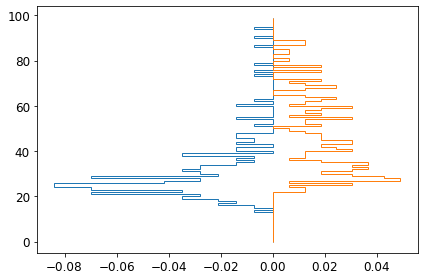

In [10]:
h, edges =np.histogram(IMTs[0]["IMT_t"], bins=range(0,100), density=True)
out = plt.stairs(-h, edges, orientation="horizontal")

h, edges =np.histogram(IMTs[1]["IMT_t"], bins=range(0,100), density=True)
out = plt.stairs(h, edges, orientation="horizontal")

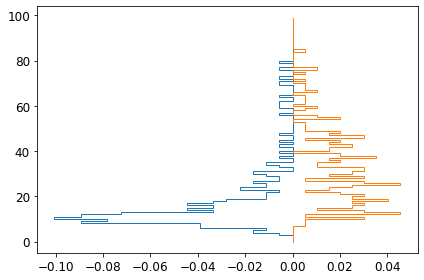

In [11]:
h, edges =np.histogram(IMTs[0]["G1_t"], bins=range(0,100), density=True)
out = plt.stairs(-h, edges, orientation="horizontal")

h, edges =np.histogram(IMTs[1]["G1_t"], bins=range(0,100), density=True)
out = plt.stairs(h, edges, orientation="horizontal")

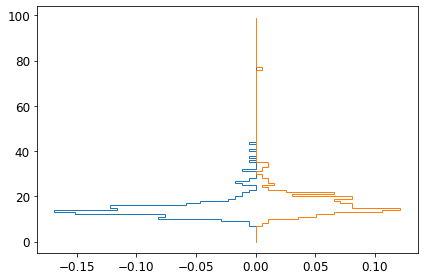

In [12]:
h, edges =np.histogram(IMTs[0]["S-M_t"], bins=range(0,100), density=True)
out = plt.stairs(-h, edges, orientation="horizontal")

h, edges =np.histogram(IMTs[1]["S-M_t"], bins=range(0,100), density=True)
out = plt.stairs(h, edges, orientation="horizontal")

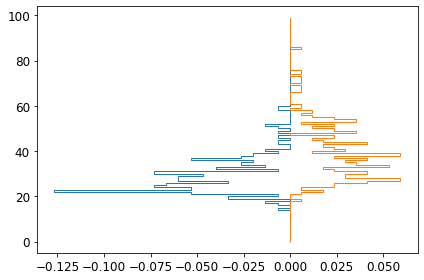

In [13]:
h, edges =np.histogram(IMTs[2]["IMT_t"], bins=range(0,100), density=True)
out = plt.stairs(-h, edges, orientation="horizontal")

h, edges =np.histogram(IMTs[3]["IMT_t"], bins=range(0,100), density=True)
out = plt.stairs(h, edges, orientation="horizontal")

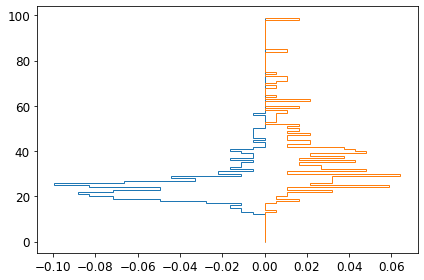

In [14]:
h, edges =np.histogram(IMTs[4]["IMT_t"], bins=range(0,100), density=True)
out = plt.stairs(-h, edges, orientation="horizontal")

h, edges =np.histogram(IMTs[5]["IMT_t"], bins=range(0,100), density=True)
out = plt.stairs(h, edges, orientation="horizontal")

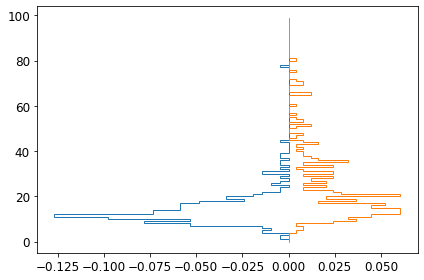

In [15]:
h, edges =np.histogram(IMTs[4]["G1_t"], bins=range(0,100), density=True)
out = plt.stairs(-h, edges, orientation="horizontal")

h, edges =np.histogram(IMTs[5]["G1_t"], bins=range(0,100), density=True)
out = plt.stairs(h, edges, orientation="horizontal")